In [1]:
import os

workdir = '/vast/ai_projects/Papenfuss_SVEnsemble2/model'
os.chdir(workdir)
os.getcwd()

'/vast/ai_projects/Papenfuss_SVEnsemble2/model'

In [2]:
import copy
import importlib

In [3]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import pyranges as pr
import sklearn

In [4]:
from sklearn.ensemble import RandomForestClassifier as RF
import sklearn.model_selection as skm
from sklearn.metrics import confusion_matrix

In [5]:
# The idea:
# 1. Split the dataset into a validation and training dataset
# 2. Train a non-traditional classifier (on the training dataset)
# 3. Estimate label frequency by applying the nontraditional classifier
# on the validation dataset and calculate class prior
# 4. Use class prior for weighing the training dataset and train again
# In Du Plessis paper there is a risk function - see nalysis of Learning from Positive and Unlabeled Data

In [6]:
df_path = 'saved/gridss_overlaps.tsv'
callset_overlapped_df = pd.read_csv(df_path, sep='\t', index_col='ID')

In [7]:
X = pd.get_dummies(callset_overlapped_df.drop(columns=['ref_matched']))
y = callset_overlapped_df['ref_matched']
X_train, X_val, y_train, y_val = skm.train_test_split(X, y, train_size=0.8, random_state=0)

In [21]:
X

,QUAL,FORMAT_ASRP,FORMAT_ASSR,FORMAT_BAQ,FORMAT_BASRP,FORMAT_BASSR,FORMAT_CASQ,FORMAT_IC,FORMAT_IQ,FORMAT_QUAL,...,INFO_MQX,INFO_RF,INFO_RP,INFO_RPQ,INFO_SR,INFO_SRQ,INFO_VF,length,REF_N,ALT_<DEL>
ID,,,,,,,,,,,,,,,,,,,,,
gridss0fb_1029,2725.38,0,64,0.0,0,0,0.00,12,636.13,2725.38,...,60.0,0,1,14.92,6,112.22,45,29,True,True
gridss0fb_1143,1697.97,0,44,0.0,0,0,0.00,10,422.84,1697.97,...,60.0,0,0,0.00,0,0.00,34,19,True,True
gridss0fb_1212,62.87,0,0,0.0,0,0,0.00,2,62.87,62.87,...,60.0,0,0,0.00,0,0.00,2,9,True,True
gridss0fb_1288,418.53,2,10,0.0,0,0,0.00,2,102.05,418.53,...,60.0,0,2,29.75,1,19.10,11,27,True,True
gridss0fb_133,197.05,0,0,0.0,0,0,0.00,0,0.00,197.05,...,60.0,0,13,197.05,0,0.00,13,223222762,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
gridss300fb_11,154.74,7,0,0.0,0,0,154.74,0,0.00,154.74,...,60.0,0,0,0.00,0,0.00,7,23,True,True
gridss300fb_6,103.00,5,0,0.0,0,0,103.00,0,0.00,103.00,...,60.0,0,0,0.00,0,0.00,5,13,True,True
gridss301fb_2,180.00,9,0,0.0,0,0,180.00,0,0.00,180.00,...,60.0,0,0,0.00,0,0.00,9,13,True,True


In [8]:
RF_nontrad = RF(max_features=int(np.sqrt(X.shape[1])), random_state=0)
RF_nontrad_fit = RF_nontrad.fit(X_train, y_train)
y_nontrad = RF_nontrad_fit.predict(X_val)

In [9]:
label_freq = sum(y_nontrad & y_val) / sum(y_val)
label_prob = sum(y) / len(y)
clpr = label_prob / label_freq

In [10]:
# Weight for True: 2 * clpr / label_prob
# Weight for False: 1 / (1 - label_prob)

In [11]:
weight_dict = {
    0: 1 / (1 - label_prob),
    1: 2 * clpr / label_prob
}
RF_duplessis = RF(
    max_features=int(np.sqrt(X.shape[1])), random_state=0,
    class_weight=weight_dict, n_estimators=200
)
RF_duplessis_fit = RF_duplessis.fit(X_train, y_train)

In [12]:
y_duplessis = RF_duplessis_fit.predict_proba(X)[:,1]

In [13]:
pd.Series(y_duplessis).to_csv('saved/y_duplessis.csv')

In [19]:
import time

import numpy as np

start_time = time.time()
importances = RF_duplessis_fit.feature_importances_
std = np.std([tree.feature_importances_ for tree in RF_duplessis_fit.estimators_], axis=0)
elapsed_time = time.time() - start_time

print(f"Elapsed time to compute the importances: {elapsed_time:.3f} seconds")

Elapsed time to compute the importances: 0.039 seconds


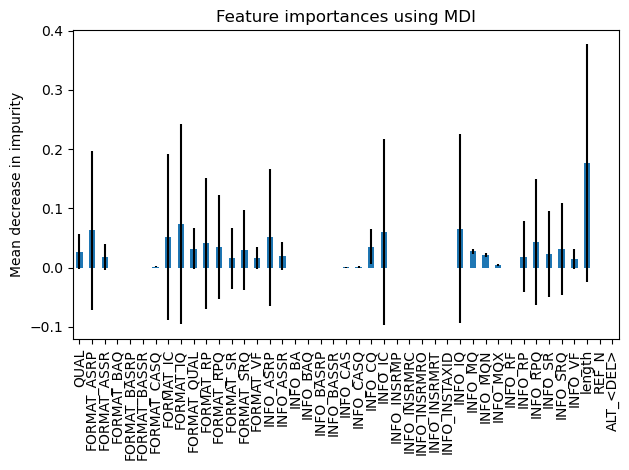

In [24]:
import pandas as pd
import matplotlib.pyplot as plt

forest_importances = pd.Series(importances, index=X.columns)

fig, ax = plt.subplots()
forest_importances.plot.bar(yerr=std, ax=ax)
ax.set_title("Feature importances using MDI")
ax.set_ylabel("Mean decrease in impurity")
fig.tight_layout()

In [26]:
from sklearn.inspection import permutation_importance

start_time = time.time()
result = permutation_importance(
    RF_duplessis_fit, X_val, y_val, n_repeats=10, random_state=42, n_jobs=2
)
elapsed_time = time.time() - start_time
print(f"Elapsed time to compute the importances: {elapsed_time:.3f} seconds")

forest_importances = pd.Series(result.importances_mean, index=X.columns)

fig, ax = plt.subplots()
forest_importances.plot(yerr=result.importances_std, ax=ax, kind='bar')
ax.set_title("Feature importances using permutation on full model")
ax.set_ylabel("Mean accuracy decrease")
fig.tight_layout()
plt.show()

Elapsed time to compute the importances: 29.594 seconds


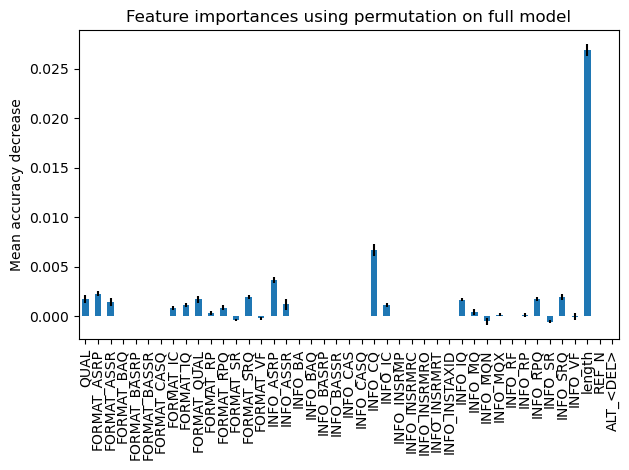

In [14]:
# I am not sure it is possible to do a custom loss function in sklearn - I DO NOT NEED TO, I CAN JUST USE WEIGHTS FOR DUPLESSIS CORRECTION
# So I implement Elkan and Noto sample weighting scheme
# Where unlabeled samples are split into 2:
# - positive part with weight (1 - label_freq) / label_freq * y_nontrad / (1 - y_nontrad)
# - negative part with weight 1 - positive_weight

In [15]:
y_proba_nontrad = RF_nontrad.predict_proba(X_train)
pos_weights = y_proba_nontrad[:, 1]
pos_weights[y_train] = 1

In [48]:
# We double the unlabeled part of X and y and give negative weights to it
X_train_neg = X_train[y_train == False]
y_train_neg = y_train[y_train == False]
neg_weights = y_proba_nontrad[y_train == False, 0]
X_doubled = pd.concat([X_train, X_train_neg])
y_doubled = np.concatenate([y_train, y_train_neg])
weights_doubled = np.concatenate([pos_weights, neg_weights])
RF_enoto = RF(
    max_features=int(np.sqrt(X.shape[1])), random_state=0
)
RF_enoto_fit = RF_enoto.fit(X_doubled, y_doubled, sample_weight=weights_doubled)

In [49]:
X_doubled

,QUAL,FORMAT_ASRP,FORMAT_ASSR,FORMAT_BAQ,FORMAT_BASRP,FORMAT_BASSR,FORMAT_CASQ,FORMAT_IC,FORMAT_IQ,FORMAT_QUAL,...,INFO_MQX,INFO_RF,INFO_RP,INFO_RPQ,INFO_SR,INFO_SRQ,INFO_VF,length,REF_N,ALT_<DEL>
ID,,,,,,,,,,,,,,,,,,,,,
gridss230fb_1981,2481.20,0,37,0.0,0,0,0.0,32,1199.75,2481.20,...,60.0,0,0,0.00,0,0.00,37,13,True,True
gridss123fb_5796,1058.74,0,15,0.0,0,0,0.0,12,482.75,1058.74,...,60.0,0,3,44.98,0,0.00,18,19,True,True
gridss75fb_4864,2113.73,0,42,0.0,0,0,0.0,18,671.67,2113.73,...,60.0,0,0,0.00,0,0.00,24,13,True,True
gridss185fb_3184,557.07,0,13,0.0,0,0,0.0,4,186.38,557.07,...,60.0,0,0,0.00,0,0.00,9,29,True,True
gridss195fb_1654,1061.49,0,18,0.0,0,0,0.0,9,353.83,1061.49,...,60.0,0,0,0.00,0,0.00,9,15,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
gridss246fb_6294,879.96,0,20,0.0,0,0,0.0,8,312.52,879.96,...,60.0,0,0,0.00,1,17.83,20,15,True,True
gridss153fb_5862,697.24,0,10,0.0,0,0,0.0,6,255.50,697.24,...,60.0,0,0,0.00,1,18.40,7,19,True,True
gridss114fb_5558,677.10,0,17,0.0,0,0,0.0,3,153.08,677.10,...,60.0,0,1,14.94,0,0.00,15,27,True,True


In [50]:
y_enoto = RF_enoto_fit.predict_proba(X)[:,1]

In [69]:
pd.Series(y_enoto).to_csv('saved/y_enoto.csv')

Elapsed time to compute the importances: 14.989 seconds


ValueError: hbar is not a valid plot kind Valid plot kinds: ('line', 'bar', 'barh', 'kde', 'density', 'area', 'hist', 'box', 'pie', 'scatter', 'hexbin')

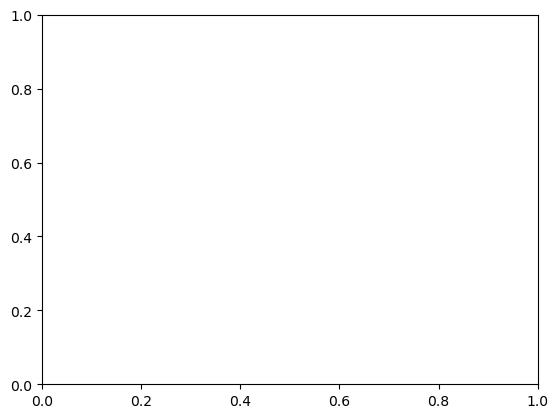

In [54]:
from sklearn.inspection import permutation_importance

start_time = time.time()
result = permutation_importance(
    RF_enoto_fit, X_val, y_val, n_repeats=10, random_state=42, n_jobs=2
)
elapsed_time = time.time() - start_time
print(f"Elapsed time to compute the importances: {elapsed_time:.3f} seconds")

forest_importances = pd.Series(result.importances_mean, index=X.columns)

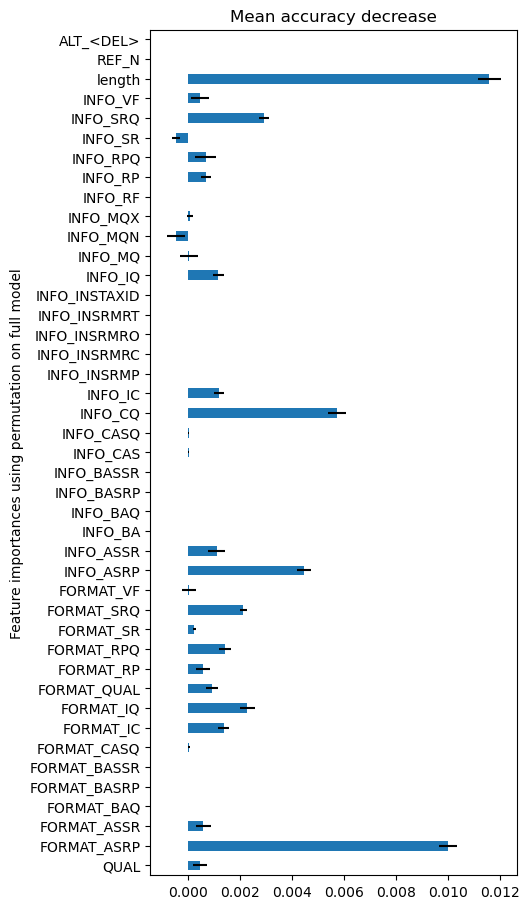

In [68]:

fig, ax = plt.subplots()
forest_importances.plot(xerr=result.importances_std, ax=ax, kind='barh')
ax.set_title("Mean accuracy decrease")
ax.set_ylabel("Feature importances using permutation on full model")

fig.tight_layout()
fig.set_size_inches((5,10))
plt.show()
# plt.show()
# plt.savefig('figs/featureimportance_perm.enoto.png')

In [52]:
disp = CalibrationDisplay(prob_true, prob_pred, y_prob)
disp.plot()

<Figure size 1000x600 with 0 Axes>